# SYS818 – Projet 1 : analyse des filtres (somme / gradient)
Notebook Colab basé sur le code du prof (`utils/utils.py` : `get_filter`, `getSymAntiSymTF`, `getDominantAngle`).

0. Installation + clone du dépôt
1. Imports
2. Données de test (à remplacer par le générateur)
3. Modèles (non entraîné + entraîné)
4. Statistiques par couche (β, Σ, DCT)
5. Graphiques β (avant / après entraînement)
6. Énergie par composante DCT
7. Orientation dominante (`getDominantAngle`)
8. Analyse par classe (tableau prédiction vs observation)
9. Plusieurs graines (barres d'erreur)


## 0. Installation + clone du dépôt

In [ ]:
import os
# Keras 2 (legacy) pour éviter les conflits avec tensorflow_probability, importé par utils.py
os.environ["TF_USE_LEGACY_KERAS"] = "1"

!pip -q install tensorflow-probability tf-keras scienceplots

REPO = "/content/Information-Mechanics"
if not os.path.exists(REPO):
    !git clone https://github.com/mt3000/Information-Mechanics.git {REPO}
%cd {REPO}

Cloning into '/content/Information-Mechanics'...
remote: Enumerating objects: 2106, done.
remote: Counting objects: 100% (111/111), done.
remote: Compressing objects: 100% (96/96), done.
remote: Total 2106 (delta 29), reused 82 (delta 12), pack-reused 1995 (from 1)
Receiving objects: 100% (2106/2106), 137.20 MiB | 16.69 MiB/s, done.
Resolving deltas: 100% (1260/1260), done.
/content/Information-Mechanics


## 1. Imports (dont les fonctions du prof)

In [ ]:
import sys, inspect
sys.path.insert(0, "/content/Information-Mechanics")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from scipy import fft
from tensorflow import keras
from tensorflow.keras import layers

from utils.utils import get_filter, getSymAntiSymTF, getDominantAngle
print("TF", tf.__version__, "| utils du prof importé")

# Vérification rapide : leur décomposition respecte Pythagore et l'orthogonalité
F = np.random.randn(3, 3, 4, 5).astype("float32")
sym, anti = getSymAntiSymTF(F)
sym, anti = np.asarray(sym), np.asarray(anti)
print("||F||² = ||sym||² + ||anti||² :", np.allclose((F**2).sum(), (sym**2).sum() + (anti**2).sum(), atol=1e-3))
print("orthogonalité <sym, anti> ≈ 0 :", abs((sym*anti).sum()) < 1e-3)

TF 2.21.0 | utils du prof importé
||F||² = ||sym||² + ||anti||² : True
orthogonalité <sym, anti> ≈ 0 : True


## 2. Données de test (à remplacer par le générateur)
Classes : 0 = barres horizontales, 1 = barres verticales, 2 = damier fin, 3 = damier large.

In [ ]:
CLASSES = ["barres H", "barres V", "damier fin", "damier large"]

def make_dataset(n=2000, size=32, seed=0, noise=0.1):
    rng = np.random.default_rng(seed)
    X, y = [], []
    yy, xx = np.mgrid[:size, :size]
    for _ in range(n):
        c = rng.integers(0, 4); p = rng.integers(0, 6)
        if c == 0: img = ((yy + p) // 2 % 2)                      # varie selon les lignes
        if c == 1: img = ((xx + p) // 2 % 2)                      # varie selon les colonnes
        if c == 2: img = (((yy + p) // 2 + (xx + p) // 2) % 2)
        if c == 3: img = (((yy + p) // 6 + (xx + p) // 6) % 2)
        X.append(img.astype("float32") + rng.normal(0, noise, (size, size))); y.append(c)
    return np.array(X)[..., None], np.array(y)                   # (N, 32, 32, 1)

Xtr, ytr = make_dataset(3000, seed=0)
Xte, yte = make_dataset(500, seed=1)
print(Xtr.shape, ytr.shape, Xte.shape, yte.shape)

(3000, 32, 32, 1) (3000,) (500, 32, 32, 1) (500,)


## 3. Modèles : un non entraîné (référence « initialisation ») et un entraîné
Filtres 3×3 et `use_bias=True` obligatoires (`get_filter` ne garde que les 3×3 et lit `filters, biases`).

In [ ]:
N_LAYERS = 3

def build_cnn(depth=N_LAYERS, ch=16, n_classes=4):
    inp = keras.Input((32, 32, 1)); x = inp
    for _ in range(depth):
        x = layers.Conv2D(ch, 3, padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    return keras.Model(inp, layers.Dense(n_classes)(x))

def compile_fit(m, epochs=15, verbose=2):
    m.compile("adam", keras.losses.SparseCategoricalCrossentropy(from_logits=True), ["accuracy"])
    m.fit(Xtr, ytr, epochs=epochs, batch_size=64, validation_data=(Xte, yte), verbose=verbose)
    return m

tf.keras.utils.set_random_seed(0)
model0 = build_cnn()                  # jamais entraîné
model  = compile_fit(build_cnn())     # entraîné
# model.save("cnn.keras")             # format d'échange avec ton binôme

Epoch 1/15
47/47 - 12s - loss: 1.1815 - accuracy: 0.5860 - val_loss: 0.7508 - val_accuracy: 0.7540 - 12s/epoch - 261ms/step
Epoch 2/15
47/47 - 7s - loss: 0.3119 - accuracy: 0.9580 - val_loss: 0.0429 - val_accuracy: 1.0000 - 7s/epoch - 142ms/step
Epoch 3/15
47/47 - 6s - loss: 0.0169 - accuracy: 1.0000 - val_loss: 0.0069 - val_accuracy: 1.0000 - 6s/epoch - 120ms/step
Epoch 4/15
47/47 - 7s - loss: 0.0048 - accuracy: 1.0000 - val_loss: 0.0033 - val_accuracy: 1.0000 - 7s/epoch - 139ms/step
Epoch 5/15
47/47 - 5s - loss: 0.0026 - accuracy: 1.0000 - val_loss: 0.0020 - val_accuracy: 1.0000 - 5s/epoch - 107ms/step
Epoch 6/15
47/47 - 5s - loss: 0.0017 - accuracy: 1.0000 - val_loss: 0.0014 - val_accuracy: 1.0000 - 5s/epoch - 108ms/step
Epoch 7/15
47/47 - 6s - loss: 0.0012 - accuracy: 1.0000 - val_loss: 0.0010 - val_accuracy: 1.0000 - 6s/epoch - 137ms/step
Epoch 8/15
47/47 - 6s - loss: 8.7845e-04 - accuracy: 1.0000 - val_loss: 7.6420e-04 - val_accuracy: 1.0000 - 6s/epoch - 118ms/step
Epoch 9/15
47/

## 4. Statistiques par couche (avec `getSymAntiSymTF` du prof)

In [ ]:
POS = [(0,0),(0,1),(1,0),(1,1),(0,2),(2,0),(1,2),(2,1),(2,2)]       # même ordre que random_full.ipynb
NAMES = ["dc","c1","c2","c3","c4","c5","c6","c7","c8"]
coords = np.array([-1, 0, 1])
XX, YY = np.meshgrid(coords, coords)       # XX : colonnes (x), YY : lignes (y)

def layer_stats(m, l):
    F = np.asarray(get_filter(m, l))                       # (3, 3, in, out)
    sym, anti = getSymAntiSymTF(F)
    sym, anti = np.asarray(sym), np.asarray(anti)
    nF, ns, na = [np.sqrt((A**2).sum((0, 1))) for A in (F, sym, anti)]   # (in, out)
    assert np.allclose(nF**2, ns**2 + na**2, atol=1e-4)
    return dict(
        F=F,
        beta=na / (nF + 1e-12),                            # ||anti|| / ||F||
        sigma=F.sum((0, 1)),                               # Σ (masse)
        fs_signed=ns * np.sign(F.sum((0, 1))),             # ||fs||·sign(Σ)
        gx=(F * XX[:, :, None, None]).sum((0, 1)),         # gradient horizontal
        gy=(F * YY[:, :, None, None]).sum((0, 1)),         # gradient vertical
        dct=fft.dctn(F, axes=(0, 1), norm="ortho"),        # coefficients DCT 3×3
    )

stats0 = [layer_stats(model0, l) for l in range(N_LAYERS)]
stats  = [layer_stats(model,  l) for l in range(N_LAYERS)]
for l in range(N_LAYERS):
    print(f"Couche {l}: β init = {stats0[l]['beta'].mean():.3f} | β entraîné = {stats[l]['beta'].mean():.3f}")

Couche 0: β init = 0.855 | β entraîné = 0.863
Couche 1: β init = 0.824 | β entraîné = 0.699
Couche 2: β init = 0.783 | β entraîné = 0.617


## 5. Distribution de β (avant / après entraînement)

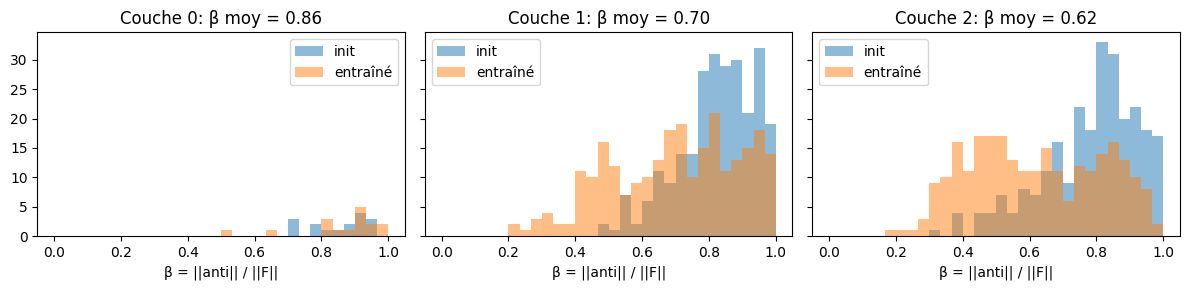

In [ ]:
fig, ax = plt.subplots(1, N_LAYERS, figsize=(4*N_LAYERS, 3), sharey=True)
for l in range(N_LAYERS):
    ax[l].hist(stats0[l]["beta"].ravel(), bins=30, range=(0, 1), alpha=.5, label="init")
    ax[l].hist(stats[l]["beta"].ravel(),  bins=30, range=(0, 1), alpha=.5, label="entraîné")
    ax[l].set_title(f"Couche {l}: β moy = {stats[l]['beta'].mean():.2f}")
    ax[l].set_xlabel("β = ||anti|| / ||F||"); ax[l].legend()
plt.tight_layout(); plt.show()

## 6. Énergie par composante DCT (dc = somme, c1/c2 = gradients du 1er ordre)

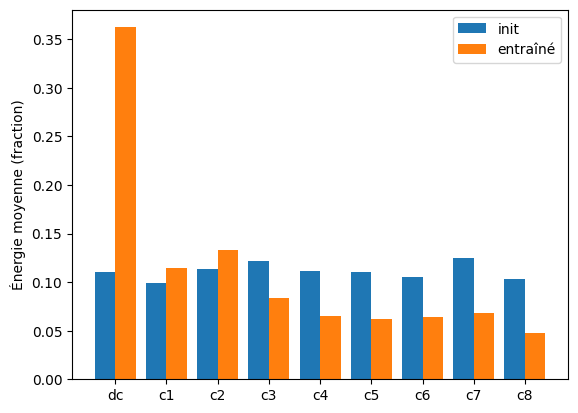

  composante   init  entraîné
0         dc  0.110     0.362
1         c1  0.100     0.114
2         c2  0.114     0.133
3         c3  0.122     0.084
4         c4  0.111     0.065
5         c5  0.110     0.062
6         c6  0.105     0.064
7         c7  0.125     0.068
8         c8  0.103     0.048


In [ ]:
def dct_energy(stats_list):
    out = np.zeros(9)
    for s in stats_list:
        e = np.array([(s["dct"][i, j]**2).sum() for i, j in POS])
        out += e / e.sum()
    return out / len(stats_list)

e0, e1 = dct_energy(stats0), dct_energy(stats)
x = np.arange(9)
plt.bar(x - .2, e0, .4, label="init"); plt.bar(x + .2, e1, .4, label="entraîné")
plt.xticks(x, NAMES); plt.ylabel("Énergie moyenne (fraction)"); plt.legend(); plt.show()
print(pd.DataFrame({"composante": NAMES, "init": e0, "entraîné": e1}).round(3))

## 7. Orientation dominante (`getDominantAngle` du prof)
Attention : `getDominantAngle` calcule une covariance sur les canaux d'entrée. Pour la couche 0 (1 seul canal d'entrée) elle donne NaN, donc on utilise l'angle du gradient `arctan2(gy, gx)` à la place.

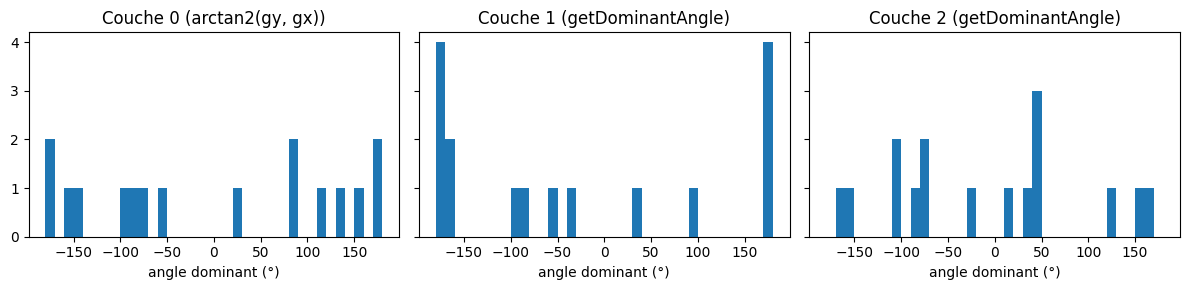

In [ ]:
fig, ax = plt.subplots(1, N_LAYERS, figsize=(4*N_LAYERS, 3), sharey=True)
for l in range(N_LAYERS):
    F = np.asarray(get_filter(model, l))
    try:
        if F.shape[2] == 1:
            s = stats[l]
            theta = np.arctan2(s["gy"][0], s["gx"][0])              # repli couche 0
            src = "arctan2(gy, gx)"
        else:
            vec, theta = getDominantAngle(F)                        # code du prof
            theta = np.asarray(theta); src = "getDominantAngle"
        ax[l].hist(np.degrees(theta), bins=36, range=(-180, 180))
        ax[l].set_title(f"Couche {l} ({src})")
        ax[l].set_xlabel("angle dominant (°)")
    except Exception as e:
        print(f"Couche {l}: erreur getDominantAngle ->", repr(e))
plt.tight_layout(); plt.show()

## 8. Analyse par classe : quels filtres s'activent pour quel motif ?
Pour chaque classe, on pondère les filtres de la couche par l'activation moyenne de leur canal de sortie, puis on regarde β, |gx|, |gy|.
**Il faut écrire nos prédictions dans la dernière cellule *avant* de lire ce tableau.**

In [ ]:
conv_layers = [l for l in model.layers if isinstance(l, layers.Conv2D)]
act_model = keras.Model(model.input, [l.output for l in conv_layers])

rows = []
for c, name in enumerate(CLASSES):
    acts = act_model.predict(Xte[yte == c], verbose=0)
    for l in range(N_LAYERS):
        w = acts[l].mean((0, 1, 2))                       # activation moyenne par canal de sortie (out,)
        w = w / (w.sum() + 1e-12)
        s = stats[l]
        beta_o = s["beta"].mean(0)                        # β moyen par filtre de sortie
        ax_o, ay_o = np.abs(s["gx"]).mean(0), np.abs(s["gy"]).mean(0)
        rows.append(dict(classe=name, couche=l,
                         beta=(w * beta_o).sum(),
                         abs_gx=(w * ax_o).sum(), abs_gy=(w * ay_o).sum(),
                         part_gx=(w * ax_o).sum() / ((w * (ax_o + ay_o)).sum() + 1e-12)))
tab = pd.DataFrame(rows)
tab.round(3)

,classe,couche,beta,abs_gx,abs_gy,part_gx
0,barres H,0,0.794,0.483,0.527,0.478
1,barres H,1,0.608,0.156,0.178,0.466
2,barres H,2,0.606,0.173,0.186,0.482
3,barres V,0,0.787,0.579,0.348,0.625
4,barres V,1,0.648,0.213,0.156,0.577
5,barres V,2,0.592,0.171,0.148,0.537
6,damier fin,0,0.792,0.531,0.367,0.591
7,damier fin,1,0.634,0.176,0.156,0.530
8,damier fin,2,0.614,0.174,0.161,0.519
9,damier large,0,0.782,0.533,0.421,0.559


In [ ]:
# Résumé couche 0 : prédiction attendue -> barres H : gy domine (part_gx faible) ; barres V : gx domine (part_gx élevé)
tab[tab.couche == 0].round(3)

,classe,couche,beta,abs_gx,abs_gy,part_gx
0,barres H,0,0.794,0.483,0.527,0.478
3,barres V,0,0.787,0.579,0.348,0.625
6,damier fin,0,0.792,0.531,0.367,0.591
9,damier large,0,0.782,0.533,0.421,0.559


## 9. Plusieurs graines (barres d'erreur sur β)

accuracy : 1.000 ± 0.000
Couche 0: β = 0.856 ± 0.019
Couche 1: β = 0.665 ± 0.028
Couche 2: β = 0.641 ± 0.024


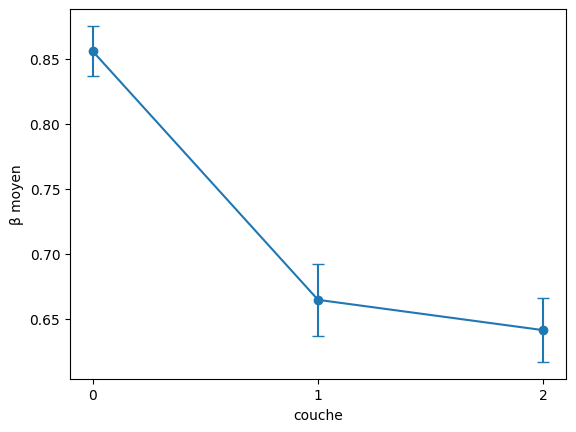

In [ ]:
betas = {l: [] for l in range(N_LAYERS)}
accs = []
for seed in range(5):
    tf.keras.utils.set_random_seed(seed)
    m = compile_fit(build_cnn(), epochs=10, verbose=0)
    accs.append(m.evaluate(Xte, yte, verbose=0)[1])
    for l in range(N_LAYERS):
        betas[l].append(layer_stats(m, l)["beta"].mean())
print("accuracy : %.3f ± %.3f" % (np.mean(accs), np.std(accs)))
for l in range(N_LAYERS):
    print(f"Couche {l}: β = {np.mean(betas[l]):.3f} ± {np.std(betas[l]):.3f}")
plt.errorbar(range(N_LAYERS), [np.mean(betas[l]) for l in range(N_LAYERS)],
             yerr=[np.std(betas[l]) for l in range(N_LAYERS)], fmt="o-", capsize=4)
plt.xlabel("couche"); plt.ylabel("β moyen"); plt.xticks(range(N_LAYERS)); plt.show()

## Prédictions (à remplir AVANT de lire les résultats)
| Motif | Composantes attendues | Observation | Prédiction correcte ? |
|---|---|---|---|
| Barres horizontales | | | |
| Barres verticales | | | |
| Damier fin | | | |
| Damier large | | | |
| Effet du bruit | | | |